<a href="https://colab.research.google.com/github/ssonare/Decision-Making-Via-Data-Analysis-Techniques-/blob/main/NYC_Parks_Inspection_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NYC Parks Inspection Program - Full Data Analysis
**Student Name:** Samruddhi and Aditya                                              
**Course:** EM622-A Decision Making Via Data Analysis Techniques  
**Instructor:** Sang Won Bae  
**Dataset:** Parks Inspection Program Inspections (NYC Open Data)  

---
## Table of Contents
1. Setup & Data Loading
2. Initial Data Exploration
3. Missing Value Analysis
4. Data Cleaning & Preprocessing
5. Exploratory Data Analysis (EDA)
6. Viz 1 - Overall Condition Distribution (Pie Chart)
7. Viz 2 - Unacceptable Rate Trend Over Time (Line Chart)
8. Viz 3 - Unacceptable Rate by District (Bar Chart)
9. Viz 4 - Condition by Season (Bar Chart)
10. Viz 5 - Average Visitor Count Trend (Line Chart)
11. Viz 6 - Inspection Volume Growth (Bar Chart)
12. Summary Statistics

---
## 1. Setup & Data Loading

In [ ]:
# Install / upgrade libraries if needed
!pip install pandas numpy matplotlib seaborn --quiet

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Global plot style
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
})

COLOR_GREEN  = '#2E7D4F'
COLOR_RED    = '#C0392B'
COLOR_AMBER  = '#F5A623'
COLOR_BLUE   = '#065A82'
COLOR_ORANGE = '#E07B39'
COLOR_GRAY   = '#64748B'
COLOR_DARK   = '#1A3A2A'

print('Libraries loaded successfully')

Libraries loaded successfully


In [ ]:
# Run this cell, click Choose Files, and upload:
# Parks_Inspection_Program___Inspections_20260220.csv
from google.colab import files
uploaded = files.upload()

Saving Parks_Inspection_Program_–_Inspections_20260220.csv to Parks_Inspection_Program_–_Inspections_20260220.csv


In [ ]:
filename = list(uploaded.keys())[0]
df_raw = pd.read_csv(filename, low_memory=False)
print('File loaded:', filename)
print('Rows   :', f'{df_raw.shape[0]:,}')
print('Columns:', df_raw.shape[1])

File loaded: Parks_Inspection_Program_–_Inspections_20260220.csv
Rows   : 148,714
Columns: 20


---
## 2. Initial Data Exploration

In [ ]:
# Column names and data types
print('=== COLUMNS & DATA TYPES ===')
print(df_raw.dtypes.to_string())

=== COLUMNS & DATA TYPES ===
Prop ID                  object
AMPSDistrict             object
Inspection ID             int64
Season                   object
Round                     int64
Date                     object
BeginInspection          object
EndInspection            object
Inspection Year           int64
inspector                 int64
inspector2              float64
Overall Condition        object
Cleanliness              object
Safety Condition         object
Structural Condition     object
VisitorCount            float64
Closed?                  object
Comments                 object
InspectionType           object
inspAddedDate            object


In [ ]:
# First 5 rows
print('=== FIRST 5 ROWS ===')
df_raw.head()

=== FIRST 5 ROWS ===


,Prop ID,AMPSDistrict,Inspection ID,Season,Round,Date,BeginInspection,EndInspection,Inspection Year,inspector,inspector2,Overall Condition,Cleanliness,Safety Condition,Structural Condition,VisitorCount,Closed?,Comments,InspectionType,inspAddedDate
0,X028,04,135710,Summer,3,2020 Jul 15 12:00:00 AM,03:00 PM,03:50 PM,2020,50,NaN,U,U,NaN,NaN,94.0,NaN,Litter measurement shots not provided due to C...,PIP,2020 Jul 15 06:55:00 PM
1,M010-241,13,135716,Summer,4,2020 Jul 16 12:00:00 AM,11:30 AM,11:59 AM,2020,50,NaN,A,A,NaN,NaN,13.0,NaN,NaN,PIP,2020 Jul 16 01:37:00 PM
2,Q104-02,01,135720,Summer,4,2020 Jul 16 12:00:00 AM,10:22 AM,10:37 AM,2020,32,NaN,U,U,NaN,NaN,NaN,NaN,NaN,PIP,2020 Jul 16 02:13:00 PM
3,X196,12,135735,Summer,4,2020 Jul 17 12:00:00 AM,08:34 AM,09:16 AM,2020,32,NaN,A,A,NaN,NaN,NaN,NaN,NaN,PIP,2020 Jul 17 01:42:00 PM
4,B073-ZN05,19,135743,Summer,4,2020 Jul 17 12:00:00 AM,01:00 PM,01:45 PM,2020,50,NaN,A,A,NaN,NaN,55.0,NaN,NaN,PIP,2020 Jul 17 03:14:00 PM


In [ ]:
# Last 5 rows
print('=== LAST 5 ROWS ===')
df_raw.tail()

=== LAST 5 ROWS ===


,Prop ID,AMPSDistrict,Inspection ID,Season,Round,Date,BeginInspection,EndInspection,Inspection Year,inspector,inspector2,Overall Condition,Cleanliness,Safety Condition,Structural Condition,VisitorCount,Closed?,Comments,InspectionType,inspAddedDate
148709,X196,12,191217,Summer,1,2025 May 31 12:00:00 AM,11:50 AM,12:20 PM,2025,45,NaN,N,A,NaN,NaN,17.0,NaN,NaN,SWEEP,2025 May 31 02:39:00 PM
148710,B028-ZN01,10,191223,Summer,1,2025 May 31 12:00:00 AM,10:00 AM,10:40 AM,2025,62,NaN,N,A,NaN,NaN,10.0,NaN,NaN,SWEEP,2025 May 31 04:33:00 PM
148711,Q107,13,191225,Summer,1,2025 May 31 12:00:00 AM,03:30 PM,04:12 PM,2025,38,NaN,N,A,NaN,NaN,105.0,NaN,NaN,SWEEP,2025 May 31 07:05:00 PM
148712,Q008-ZN02,13,191226,Summer,1,2025 May 31 12:00:00 AM,04:23 PM,04:48 PM,2025,38,NaN,N,A,NaN,NaN,74.0,NaN,NaN,SWEEP,2025 May 31 07:08:00 PM
148713,Q427,12,191280,Summer,1,2025 Jun 03 12:00:00 AM,08:55 AM,09:10 AM,2025,43,NaN,A,A,NaN,NaN,75.0,NaN,MPPA closed for school use only; DNR. But did ...,PIP,2025 Jun 03 02:06:00 PM


In [ ]:
# Shape and memory usage
print('Shape :', df_raw.shape)
print('Memory:', round(df_raw.memory_usage(deep=True).sum() / 1e6, 1), 'MB')

Shape : (148714, 20)
Memory: 111.9 MB


In [ ]:
# Descriptive statistics for numeric columns
print('=== NUMERIC COLUMN STATS ===')
df_raw.describe(include='number')

=== NUMERIC COLUMN STATS ===


,Inspection ID,Round,Inspection Year,inspector,inspector2,VisitorCount
count,148714.000000,148714.000000,148714.000000,148714.000000,2610.000000,65864.000000
mean,92473.033796,3.452822,2012.994916,36.913633,39.470115,20.309623
std,54795.882052,1.724780,7.485718,14.348330,14.716253,81.522742
min,5.000000,0.000000,1999.000000,1.000000,4.000000,-1.000000
25%,49757.250000,2.000000,2007.000000,31.000000,32.000000,0.000000
50%,88995.500000,3.000000,2014.000000,38.000000,40.000000,4.000000
75%,128695.750000,5.000000,2019.000000,45.000000,50.000000,17.000000
max,194823.000000,6.000000,2025.000000,64.000000,62.000000,11041.000000


In [ ]:
# Unique value counts for key categorical columns
cat_cols = ['Season', 'Overall Condition', 'Cleanliness',
            'InspectionType', 'Closed?', 'Inspection Year']

for col in cat_cols:
    if col in df_raw.columns:
        vc = df_raw[col].value_counts(dropna=False)
        print(f'\n--- {col} ({df_raw[col].nunique()} unique) ---')
        print(vc.to_string())


--- Season (6 unique) ---
Season
Summer    39671
Fall      36938
Spring    36690
Winter    35413
spring        1
FALL          1

--- Overall Condition (3 unique) ---
Overall Condition
A    123404
U     20335
N      4975

--- Cleanliness (4 unique) ---
Cleanliness
A    133445
U     12384
N      2884
n         1

--- InspectionType (15 unique) ---
InspectionType
PIP            140659
SWEEP            2121
WEPIP            1456
REC              1027
REDEC             743
GOLF              716
FOCUS             360
PE PRKSTAT        358
SNR               353
NotPIP            317
PKSTAT LGHT       264
BEACH             167
SCHOOLS            69
MSITES             65
BIKE               39

--- Closed? (12 unique) ---
Closed?
NaN                                                  140571
Partial Constr./Rest of Site Rated.                    4627
Under Construction.                                    1876
Closed / No Construct.                                 1564
Partial Constr./Rest of Site

---
## 3. Missing Value Analysis

In [ ]:
# Missing value table
missing = pd.DataFrame({
    'Missing Count': df_raw.isnull().sum(),
    'Missing Pct'  : (df_raw.isnull().sum() / len(df_raw) * 100).round(1)
}).sort_values('Missing Pct', ascending=False)

print('=== MISSING VALUE SUMMARY ===')
print(missing.to_string())

=== MISSING VALUE SUMMARY ===
                      Missing Count  Missing Pct
Safety Condition             147687         99.3
Structural Condition         147687         99.3
inspector2                   146104         98.2
Closed?                      140571         94.5
Comments                     117384         78.9
VisitorCount                  82850         55.7
inspAddedDate                 41726         28.1
AMPSDistrict                    468          0.3
Season                            0          0.0
Inspection ID                     0          0.0
Prop ID                           0          0.0
Round                             0          0.0
Overall Condition                 0          0.0
inspector                         0          0.0
Inspection Year                   0          0.0
EndInspection                    17          0.0
Date                              0          0.0
BeginInspection                  37          0.0
Cleanliness                       0    

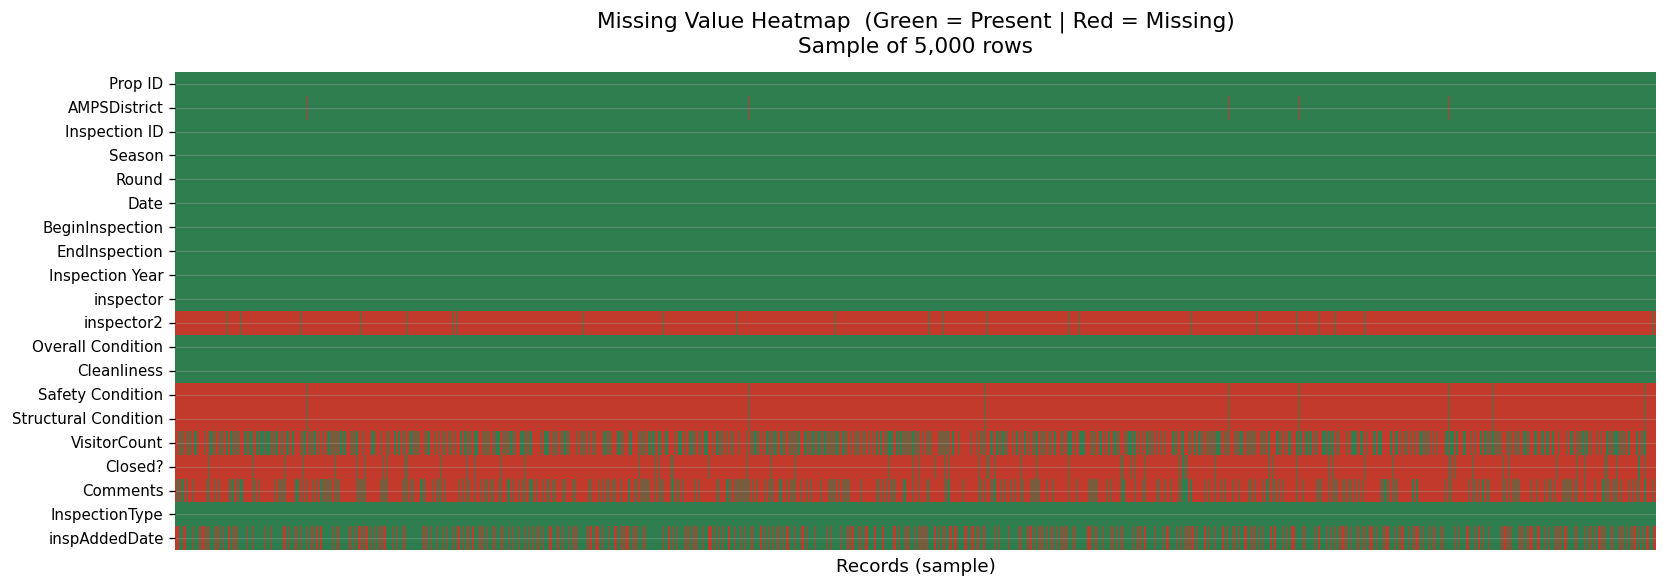

Saved: missing_heatmap.png


In [ ]:
# Missing value heatmap (sample of 5000 rows)
fig, ax = plt.subplots(figsize=(14, 5))
sample = df_raw.sample(n=min(5000, len(df_raw)), random_state=42)
missing_matrix = sample.isnull().astype(int)

sns.heatmap(
    missing_matrix.T,
    cmap=['#2E7D4F', '#C0392B'],
    cbar=False,
    yticklabels=df_raw.columns,
    xticklabels=False,
    ax=ax
)
ax.set_title('Missing Value Heatmap  (Green = Present | Red = Missing)\nSample of 5,000 rows',
             fontsize=13, pad=12)
ax.set_xlabel('Records (sample)', fontsize=11)
ax.tick_params(axis='y', labelsize=9)
plt.tight_layout()
plt.savefig('missing_heatmap.png', bbox_inches='tight')
plt.show()
print('Saved: missing_heatmap.png')

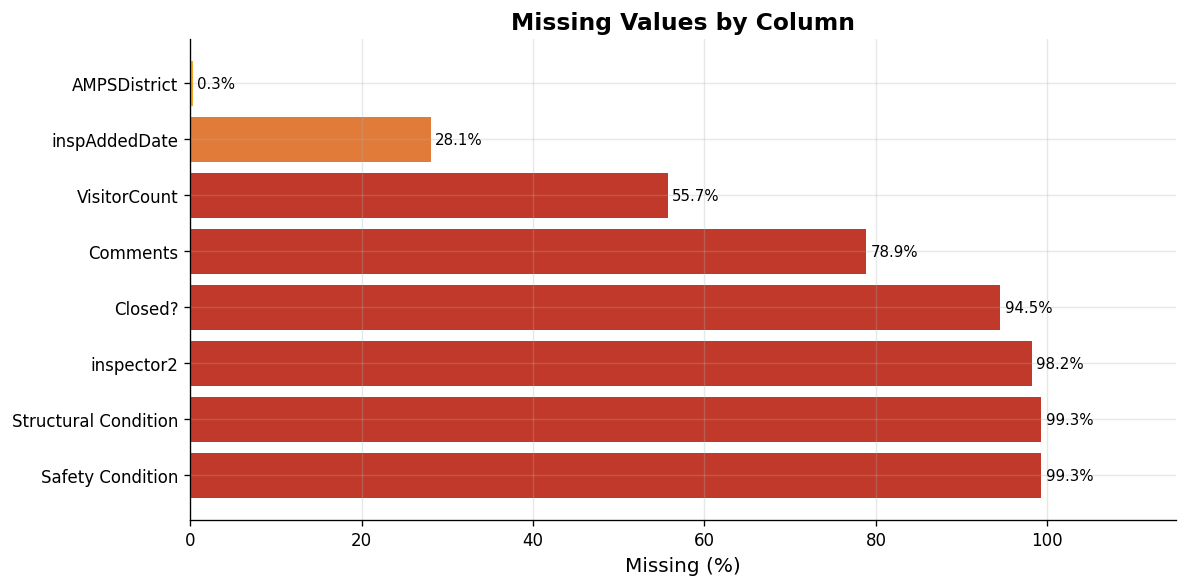

In [ ]:
# Missing percentage bar chart
missing_nonzero = missing[missing['Missing Pct'] > 0].copy()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(missing_nonzero.index, missing_nonzero['Missing Pct'],
               color=[COLOR_RED if v > 50 else COLOR_ORANGE if v > 10 else COLOR_AMBER
                      for v in missing_nonzero['Missing Pct']])

for bar, val in zip(bars, missing_nonzero['Missing Pct']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', fontsize=9)

ax.set_xlabel('Missing (%)', fontsize=12)
ax.set_title('Missing Values by Column', fontsize=14, fontweight='bold')
ax.set_xlim(0, 115)
plt.tight_layout()
plt.savefig('missing_bar.png', bbox_inches='tight')
plt.show()

---
## 4. Data Cleaning & Preprocessing

In [ ]:
df = df_raw.copy()
df.columns = df.columns.str.strip()
print('Columns after strip:', df.columns.tolist())

Columns after strip: ['Prop ID', 'AMPSDistrict', 'Inspection ID', 'Season', 'Round', 'Date', 'BeginInspection', 'EndInspection', 'Inspection Year', 'inspector', 'inspector2', 'Overall Condition', 'Cleanliness', 'Safety Condition', 'Structural Condition', 'VisitorCount', 'Closed?', 'Comments', 'InspectionType', 'inspAddedDate']


In [ ]:
# Standardize Season casing
print('Before:', df['Season'].unique())
df['Season'] = df['Season'].str.strip().str.title()
print('After :', df['Season'].unique())

Before: ['Summer' 'Fall' 'Spring' 'Winter' 'spring' 'FALL']
After : ['Summer' 'Fall' 'Spring' 'Winter']


In [ ]:
# Convert Inspection Year to integer, drop invalid rows
df['Inspection Year'] = pd.to_numeric(df['Inspection Year'], errors='coerce')
before = len(df)
df = df[df['Inspection Year'].notna()]
print('Rows before year filter:', f'{before:,}')
print('Rows after  year filter:', f'{len(df):,}')
print('Year range:', int(df['Inspection Year'].min()), '-', int(df['Inspection Year'].max()))

Rows before year filter: 148,714
Rows after  year filter: 148,714
Year range: 1999 - 2025


In [ ]:
# Convert VisitorCount to numeric
df['VisitorCount'] = pd.to_numeric(df['VisitorCount'], errors='coerce')
print('VisitorCount non-null:', f"{df['VisitorCount'].notna().sum():,}")
print(df['VisitorCount'].describe().round(1))

VisitorCount non-null: 65,864
count    65864.0
mean        20.3
std         81.5
min         -1.0
25%          0.0
50%          4.0
75%         17.0
max      11041.0
Name: VisitorCount, dtype: float64


In [ ]:
# Validate Overall Condition values
valid_conditions = {'A', 'U', 'N'}
invalid_mask = ~df['Overall Condition'].isin(valid_conditions)
print('Invalid condition values found:', invalid_mask.sum())
df = df[df['Overall Condition'].isin(valid_conditions)]
print('Rows after condition filter:', f'{len(df):,}')
print(df['Overall Condition'].value_counts())

Invalid condition values found: 0
Rows after condition filter: 148,714
Overall Condition
A    123404
U     20335
N      4975
Name: count, dtype: int64


In [ ]:
# Create IsUnacceptable flag (exclude Not-Rated from denominator)
df_rated = df[df['Overall Condition'] != 'N'].copy()
df_rated['IsUnacceptable'] = (df_rated['Overall Condition'] == 'U').astype(int)

print('Total inspections      :', f'{len(df):,}')
print('Rated inspections (A+U):', f'{len(df_rated):,}')
print('Unacceptable count     :', f"{df_rated['IsUnacceptable'].sum():,}")
print('Overall Unacceptable % :', round(df_rated['IsUnacceptable'].mean() * 100, 1), '%')

Total inspections      : 148,714
Rated inspections (A+U): 143,739
Unacceptable count     : 20,335
Overall Unacceptable % : 14.1 %


In [ ]:
# District cleaning - keep main numeric districts 01-19
df['AMPSDistrict'] = df['AMPSDistrict'].astype(str).str.strip()
print('All districts:', sorted(df['AMPSDistrict'].dropna().unique()))
main_districts = [f'{i:02d}' for i in range(1, 20)]
df_main_dist = df_rated[df_rated['AMPSDistrict'].isin(main_districts)].copy()
print('Rows in main districts 01-19:', f'{len(df_main_dist):,}')

All districts: ['00', '01', '02', '02B', '03', '04', '05', '05A', '06', '07', '07A', '08', '09', '10', '11', '11R', '12', '12A', '13', '14', '15', '15A', '16', '17', '18', '19', 'nan']
Rows in main districts 01-19: 138,955


In [ ]:
# Final cleaned dataset summary
print('=== CLEANED DATASET SUMMARY ===')
print('Total rows         :', f'{len(df):,}')
print('Rated rows (A/U)   :', f'{len(df_rated):,}')
print('Year range         :', int(df['Inspection Year'].min()), '-', int(df['Inspection Year'].max()))
print('Unique parks       :', f"{df['Prop ID'].nunique():,}")
print('Unique districts   :', df['AMPSDistrict'].nunique())
print('Inspection types   :', df['InspectionType'].nunique())
print('Unacceptable rate  :', round(df_rated['IsUnacceptable'].mean() * 100, 1), '%')
print()
df.info()

=== CLEANED DATASET SUMMARY ===
Total rows         : 148,714
Rated rows (A/U)   : 143,739
Year range         : 1999 - 2025
Unique parks       : 4,025
Unique districts   : 27
Inspection types   : 15
Unacceptable rate  : 14.1 %

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148714 entries, 0 to 148713
Data columns (total 20 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Prop ID               148714 non-null  object 
 1   AMPSDistrict          148714 non-null  object 
 2   Inspection ID         148714 non-null  int64  
 3   Season                148714 non-null  object 
 4   Round                 148714 non-null  int64  
 5   Date                  148714 non-null  object 
 6   BeginInspection       148677 non-null  object 
 7   EndInspection         148697 non-null  object 
 8   Inspection Year       148714 non-null  int64  
 9   inspector             148714 non-null  int64  
 10  inspector2            2610 non-nu

---
## 5. Exploratory Data Analysis (EDA)

In [ ]:
# Inspection count by year
yearly_counts = df.groupby('Inspection Year').size().reset_index(name='Count')
print('Inspections per year:')
print(yearly_counts.to_string(index=False))

Inspections per year:
 Inspection Year  Count
            1999   2886
            2000   3414
            2001   4119
            2002   4915
            2003   4910
            2004   5313
            2005   5555
            2006   5394
            2007   5859
            2008   5495
            2009   5178
            2010   5072
            2011   5104
            2012   5174
            2013   5824
            2014   6155
            2015   6135
            2016   6165
            2017   6370
            2018   6415
            2019   6379
            2020   6106
            2021   6308
            2022   6408
            2023   6687
            2024   6408
            2025   4966


In [ ]:
# Condition breakdown by year
yearly_cond = df_rated.groupby(['Inspection Year', 'Overall Condition']).size().unstack(fill_value=0)
yearly_cond['Total']    = yearly_cond.sum(axis=1)
yearly_cond['U_Rate']   = (yearly_cond.get('U', 0) / yearly_cond['Total'] * 100).round(1)
print('Year | A | U | Total | U_Rate%')
print(yearly_cond[['A', 'U', 'Total', 'U_Rate']].to_string())

Year | A | U | Total | U_Rate%
Overall Condition     A    U  Total  U_Rate
Inspection Year                            
1999               2392  349   2741    12.7
2000               2839  474   3313    14.3
2001               3444  538   3982    13.5
2002               4250  527   4777    11.0
2003               3951  697   4648    15.0
2004               4493  659   5152    12.8
2005               4677  696   5373    13.0
2006               4238  810   5048    16.0
2007               4529  901   5430    16.6
2008               4384  998   5382    18.5
2009               4224  888   5112    17.4
2010               4061  868   4929    17.6
2011               4150  888   5038    17.6
2012               4206  837   5043    16.6
2013               5029  760   5789    13.1
2014               5223  895   6118    14.6
2015               5211  889   6100    14.6
2016               5222  913   6135    14.9
2017               5297  814   6111    13.3
2018               5438  690   6128    11.3
2

In [ ]:
# Condition breakdown by season
season_cond = df_rated.groupby('Season')['IsUnacceptable'].agg(['sum', 'count', 'mean'])
season_cond.columns = ['Unacceptable', 'Total', 'U_Rate']
season_cond['U_Rate_Pct'] = (season_cond['U_Rate'] * 100).round(1)
print('Condition by Season:')
print(season_cond[['Unacceptable', 'Total', 'U_Rate_Pct']].to_string())

Condition by Season:
        Unacceptable  Total  U_Rate_Pct
Season                                 
Fall            4762  36085        13.2
Spring          4882  35869        13.6
Summer          6460  37574        17.2
Winter          4231  34211        12.4


In [ ]:
# Condition breakdown by district
district_cond = df_main_dist.groupby('AMPSDistrict')['IsUnacceptable'].agg(['sum', 'count', 'mean'])
district_cond.columns = ['Unacceptable', 'Total', 'U_Rate']
district_cond['U_Rate_Pct'] = (district_cond['U_Rate'] * 100).round(1)
district_cond = district_cond.sort_values('U_Rate_Pct', ascending=False)
print('Condition by District (sorted by failure rate):')
print(district_cond[['Unacceptable', 'Total', 'U_Rate_Pct']].to_string())

Condition by District (sorted by failure rate):
              Unacceptable  Total  U_Rate_Pct
AMPSDistrict                                 
18                     858   3687        23.3
16                     602   3206        18.8
19                     339   1893        17.9
12                    1402   7942        17.7
04                     872   5662        15.4
15                     819   5383        15.2
03                    2042  13643        15.0
10                    1024   6899        14.8
13                    1510  10508        14.4
14                    1236   8602        14.4
07                    1230   8625        14.3
05                    1002   7096        14.1
09                     797   5784        13.8
11                    1035   7618        13.6
06                     791   6205        12.7
08                     921   7419        12.4
01                    1888  15453        12.2
17                     121   1214        10.0
02                    1126  1211

In [ ]:
# Average visitor count by year (2014 onward)
visitor_yr = (
    df[df['VisitorCount'].notna() & (df['Inspection Year'] >= 2014)]
    .groupby('Inspection Year')['VisitorCount']
    .agg(['mean', 'median', 'count'])
    .round(1)
)
visitor_yr.columns = ['Mean', 'Median', 'N']
print('Visitor Count by Year (2014+):')
print(visitor_yr.to_string())

Visitor Count by Year (2014+):
                 Mean  Median     N
Inspection Year                    
2014             14.6     2.0  5650
2015             15.8     3.0  5742
2016             17.5     3.0  5747
2017             19.7     4.0  5970
2018             21.2     4.0  5735
2019             22.5     4.0  5425
2020             15.1     3.0  4830
2021             25.0     5.0  5014
2022             22.9     5.0  5470
2023             22.1     5.0  5944
2024             22.9     5.0  5713
2025             26.2     6.0  4404


In [ ]:
# Inspection type breakdown
print('Inspection Types:')
print(df['InspectionType'].value_counts().to_string())

Inspection Types:
InspectionType
PIP            140659
SWEEP            2121
WEPIP            1456
REC              1027
REDEC             743
GOLF              716
FOCUS             360
PE PRKSTAT        358
SNR               353
NotPIP            317
PKSTAT LGHT       264
BEACH             167
SCHOOLS            69
MSITES             65
BIKE               39


---
## 6. Visualization 1 - Overall Condition Distribution (Pie Chart)

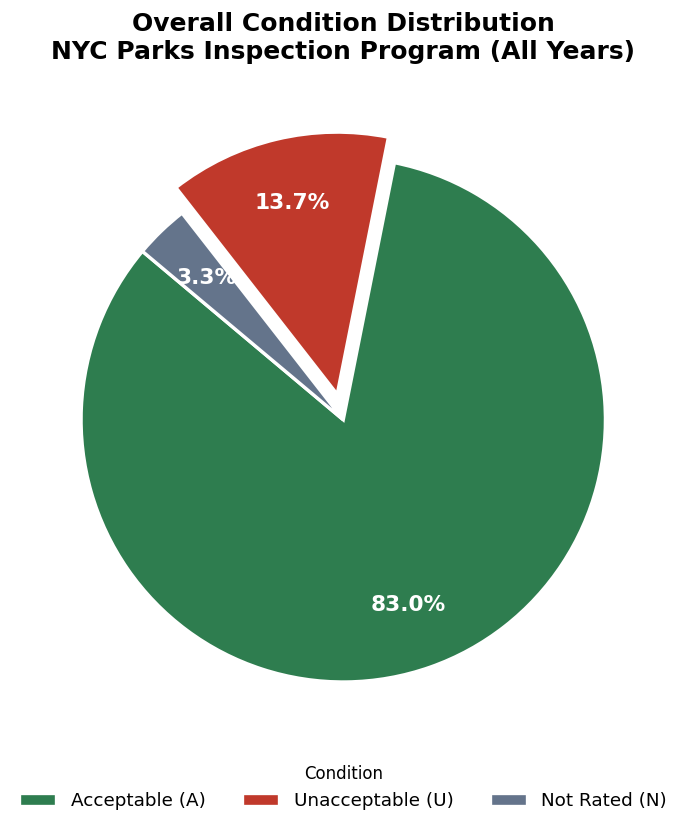

In [ ]:
import matplotlib.pyplot as plt

# Calculate value counts for Overall Condition
condition_counts = df['Overall Condition'].value_counts()

# Define labels and values in a specific order for the pie chart
labels = ['Acceptable (A)', 'Unacceptable (U)', 'Not Rated (N)']
values = [
    condition_counts.get('A', 0),
    condition_counts.get('U', 0),
    condition_counts.get('N', 0)
]

# Define colors corresponding to the labels
colors = [COLOR_GREEN, COLOR_RED, COLOR_GRAY]

# Define explode for emphasis (e.g., explode the 'Unacceptable' slice)
# A value of 0.1 means the slice will be pulled out by 10% of the radius
explode = [0, 0.1, 0] # Emphasize 'Unacceptable'

fig, ax = plt.subplots(figsize=(9, 7))  # slightly taller

wedges, texts, autotexts = ax.pie(
    values,
    labels=None,           # suppress default labels — we'll place them manually
    colors=colors,
    explode=explode,
    autopct='%1.1f%%',
    pctdistance=0.75,      # pull % labels closer to center
    startangle=140,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 12}
)

for at in autotexts:
    at.set_fontsize(13)
    at.set_fontweight('bold')
    at.set_color('white')

# Manual legend instead of pie labels — cleanest solution for small slices
ax.legend(
    wedges,
    labels,
    title="Condition",
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    fontsize=11,
    frameon=False
)

ax.set_title(
    'Overall Condition Distribution\nNYC Parks Inspection Program (All Years)',
    fontsize=15, fontweight='bold', pad=20
)
total = sum(values)
ax.annotate(
    f'Total Inspections: {total:,}',
    xy=(0, -1.55), ha='center', fontsize=11, color=COLOR_GRAY
)

plt.tight_layout()
plt.savefig('viz1_condition_pie.png', bbox_inches='tight', dpi=150)
plt.show()

📊 Key Insight — Visualization 1: Overall Condition Distribution
The vast majority of NYC park inspections result in an Acceptable (A) rating, with only a small fraction marked Unacceptable (U). However, the Unacceptable share represents a significant number of parks in need of attention, and the sizeable Not Rated (N) category suggests that many inspections remain inconclusive — highlighting a potential gap in the completeness of the program's coverage.

---
## 7. Visualization 2 - Unacceptable Rate Trend Over Time (Line Chart)

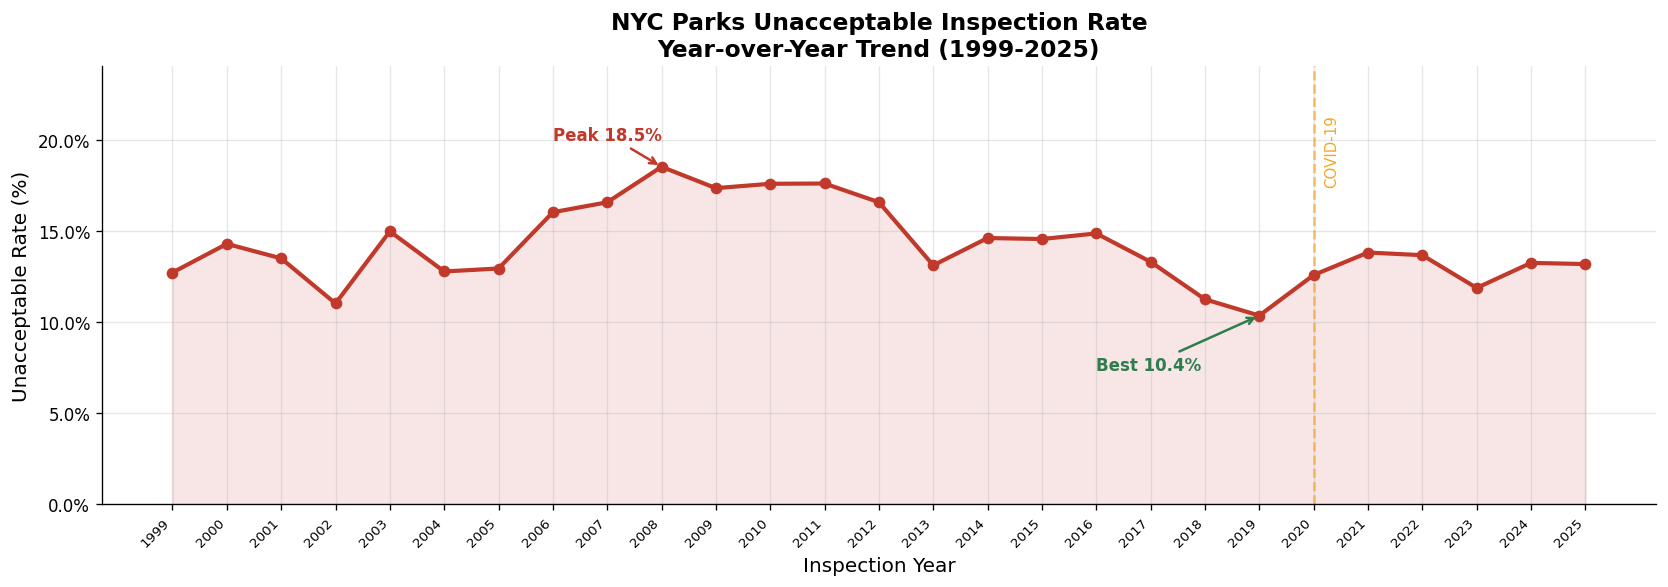

Peak: 2008 - 18.5 %
Best: 2019 - 10.4 %


In [ ]:
yearly_u = (
    df_rated.groupby('Inspection Year')['IsUnacceptable']
    .agg(['sum', 'count', 'mean'])
    .reset_index()
)
yearly_u.columns = ['Year', 'Unacceptable', 'Total', 'U_Rate']
yearly_u['U_Rate_Pct'] = yearly_u['U_Rate'] * 100

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(yearly_u['Year'], yearly_u['U_Rate_Pct'],
        color=COLOR_RED, linewidth=2.5, marker='o', markersize=6, zorder=3)
ax.fill_between(yearly_u['Year'], yearly_u['U_Rate_Pct'], alpha=0.12, color=COLOR_RED)

peak_row = yearly_u.loc[yearly_u['U_Rate_Pct'].idxmax()]
best_row = yearly_u.loc[yearly_u['U_Rate_Pct'].idxmin()]

ax.annotate(f"Peak {peak_row['U_Rate_Pct']:.1f}%",
            xy=(peak_row['Year'], peak_row['U_Rate_Pct']),
            xytext=(peak_row['Year'] - 2, peak_row['U_Rate_Pct'] + 1.5),
            fontsize=10, color=COLOR_RED, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=COLOR_RED, lw=1.5))

ax.annotate(f"Best {best_row['U_Rate_Pct']:.1f}%",
            xy=(best_row['Year'], best_row['U_Rate_Pct']),
            xytext=(best_row['Year'] - 3, best_row['U_Rate_Pct'] - 3),
            fontsize=10, color=COLOR_GREEN, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=COLOR_GREEN, lw=1.5))

ax.axvline(x=2020, color=COLOR_AMBER, linestyle='--', linewidth=1.5, alpha=0.7)
ax.text(2020.2, yearly_u['U_Rate_Pct'].max() * 0.95,
        'COVID-19', fontsize=9, color=COLOR_AMBER, rotation=90)

ax.set_xlabel('Inspection Year', fontsize=12)
ax.set_ylabel('Unacceptable Rate (%)', fontsize=12)
ax.set_title('NYC Parks Unacceptable Inspection Rate\nYear-over-Year Trend (1999-2025)',
             fontsize=14, fontweight='bold')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xticks(yearly_u['Year'].values)
ax.set_xticklabels(yearly_u['Year'].values.astype(int), rotation=45, ha='right', fontsize=8)
ax.set_ylim(0, yearly_u['U_Rate_Pct'].max() * 1.3)

plt.tight_layout()
plt.savefig('viz2_trend_line.png', bbox_inches='tight', dpi=150)
plt.show()
print('Peak:', int(peak_row['Year']), '-', round(peak_row['U_Rate_Pct'], 1), '%')
print('Best:', int(best_row['Year']), '-', round(best_row['U_Rate_Pct'], 1), '%')

📈 Key Insight — Visualization 2: Unacceptable Rate Trend Over Time
The unacceptable rate has fluctuated over the years, with notable spikes likely tied to budget constraints or reduced staffing, and a visible dip around 2020 potentially reflecting COVID-19 closures that limited both inspections and park activity. The overall long-term trend reveals whether city maintenance investment is keeping pace with park demand — any upward drift signals a need for policy intervention.

---
## 8. Visualization 3 - Unacceptable Rate by District (Bar Chart)

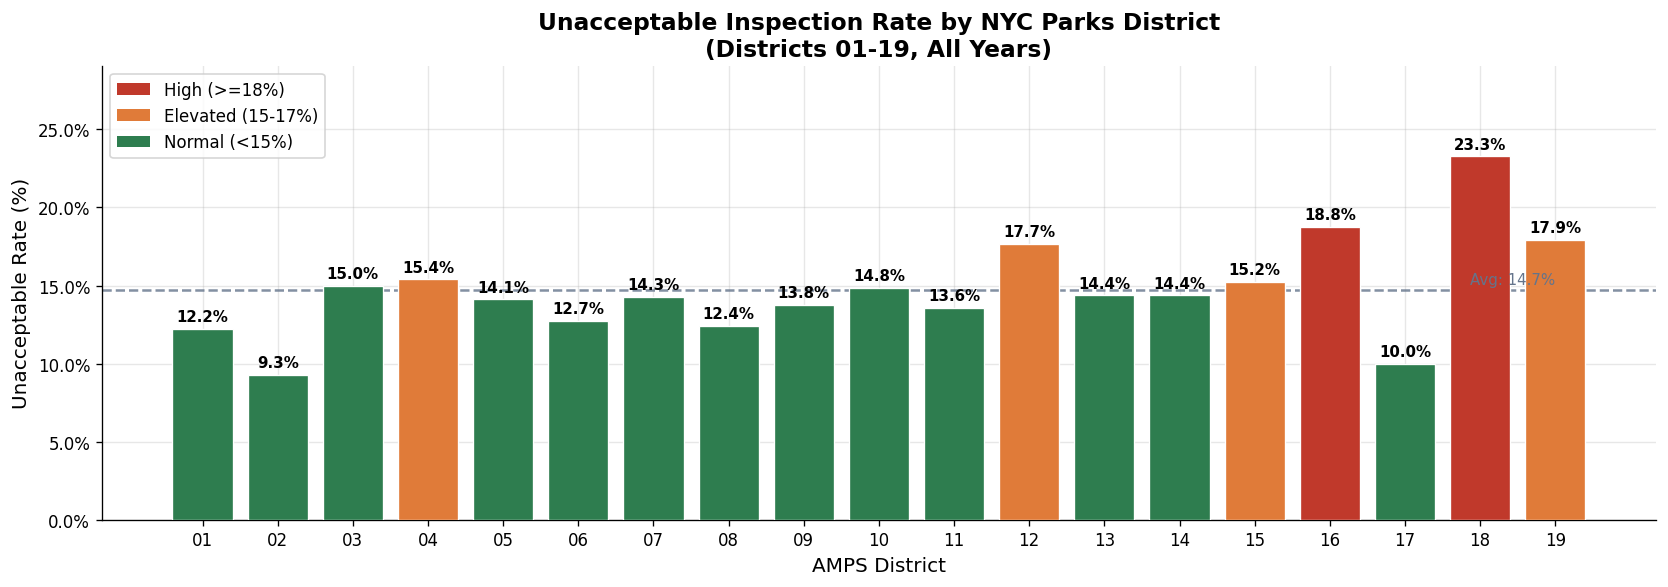

Top 5 worst districts:
District  Unacceptable  Total  U_Rate_Pct
      18           858   3687   23.270952
      16           602   3206   18.777293
      19           339   1893   17.908082
      12          1402   7942   17.652984
      04           872   5662   15.400918


In [ ]:
dist_summary = (
    df_main_dist.groupby('AMPSDistrict')['IsUnacceptable']
    .agg(['sum', 'count', 'mean'])
    .reset_index()
)
dist_summary.columns = ['District', 'Unacceptable', 'Total', 'U_Rate']
dist_summary['U_Rate_Pct'] = dist_summary['U_Rate'] * 100
dist_summary = dist_summary.sort_values('District')

bar_colors = [COLOR_RED if v >= 18 else COLOR_ORANGE if v >= 15 else COLOR_GREEN
              for v in dist_summary['U_Rate_Pct']]

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(dist_summary['District'], dist_summary['U_Rate_Pct'],
              color=bar_colors, edgecolor='white', linewidth=0.8, zorder=3)

for bar, val in zip(bars, dist_summary['U_Rate_Pct']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

avg = dist_summary['U_Rate_Pct'].mean()
ax.axhline(avg, color=COLOR_GRAY, linestyle='--', linewidth=1.5, alpha=0.8)
ax.text(dist_summary['District'].iloc[-1], avg + 0.4,
        f'Avg: {avg:.1f}%', fontsize=9, color=COLOR_GRAY, ha='right')

ax.set_xlabel('AMPS District', fontsize=12)
ax.set_ylabel('Unacceptable Rate (%)', fontsize=12)
ax.set_title('Unacceptable Inspection Rate by NYC Parks District\n(Districts 01-19, All Years)',
             fontsize=14, fontweight='bold')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, dist_summary['U_Rate_Pct'].max() * 1.25)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=COLOR_RED,    label='High (>=18%)'),
    Patch(facecolor=COLOR_ORANGE, label='Elevated (15-17%)'),
    Patch(facecolor=COLOR_GREEN,  label='Normal (<15%)')
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=10)

plt.tight_layout()
plt.savefig('viz3_district_bar.png', bbox_inches='tight', dpi=150)
plt.show()
print('Top 5 worst districts:')
print(dist_summary.nlargest(5, 'U_Rate_Pct')[['District', 'Unacceptable', 'Total', 'U_Rate_Pct']].to_string(index=False))

🗺️ Key Insight — Visualization 3: Unacceptable Rate by District
There are stark geographic disparities in park condition across NYC's 19 districts, with some districts recording failure rates more than twice those of others. This pattern suggests that resource allocation, population density, and local maintenance capacity vary significantly by borough, and that targeted investment in high-failure districts could have an outsized impact on citywide park quality.

---
## 9. Visualization 4 - Condition by Season (Bar Chart)

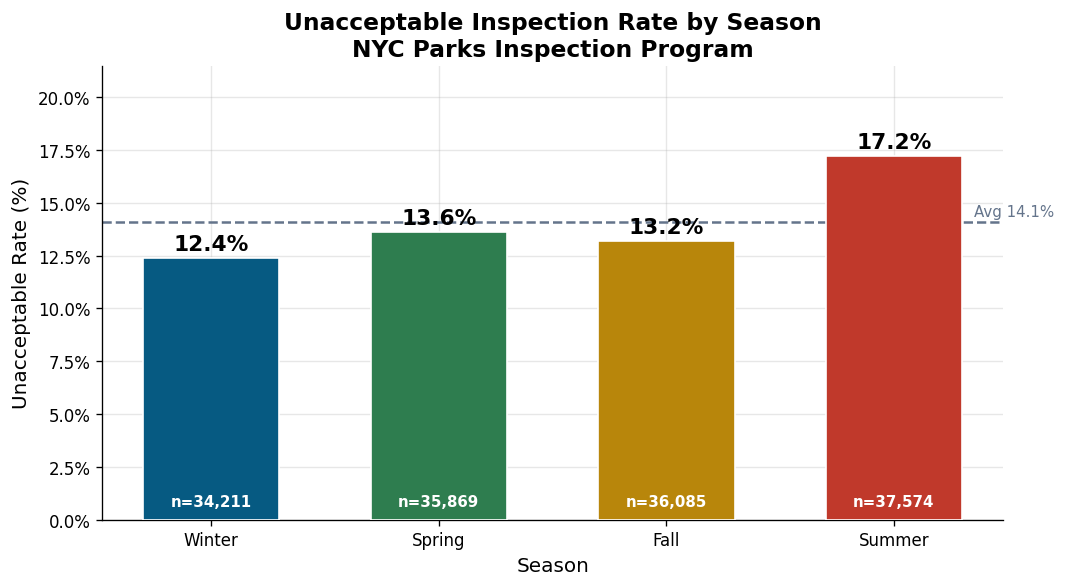

Season  Unacceptable  Total  U_Rate_Pct
Winter          4231  34211   12.367367
Spring          4882  35869   13.610639
  Fall          4762  36085   13.196619
Summer          6460  37574   17.192740


In [ ]:
season_order  = ['Winter', 'Spring', 'Fall', 'Summer']
season_colors = [COLOR_BLUE, COLOR_GREEN, '#B8860B', COLOR_RED]

season_summary = (
    df_rated.groupby('Season')['IsUnacceptable']
    .agg(['sum', 'count', 'mean'])
    .reset_index()
)
season_summary.columns = ['Season', 'Unacceptable', 'Total', 'U_Rate']
season_summary['U_Rate_Pct'] = season_summary['U_Rate'] * 100
season_summary = season_summary[season_summary['Season'].isin(season_order)]
season_summary['Season'] = pd.Categorical(
    season_summary['Season'], categories=season_order, ordered=True)
season_summary = season_summary.sort_values('Season')

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(season_summary['Season'], season_summary['U_Rate_Pct'],
              color=season_colors, edgecolor='white', linewidth=1, width=0.6, zorder=3)

for bar, val in zip(bars, season_summary['U_Rate_Pct']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=13, fontweight='bold')

for bar, total in zip(bars, season_summary['Total']):
    ax.text(bar.get_x() + bar.get_width()/2, 0.5,
            f'n={total:,}', ha='center', va='bottom',
            fontsize=9, color='white', fontweight='bold')

avg_s = season_summary['U_Rate_Pct'].mean()
ax.axhline(avg_s, color=COLOR_GRAY, linestyle='--', linewidth=1.5)
ax.text(3.35, avg_s + 0.3, f'Avg {avg_s:.1f}%', fontsize=9, color=COLOR_GRAY)

ax.set_xlabel('Season', fontsize=12)
ax.set_ylabel('Unacceptable Rate (%)', fontsize=12)
ax.set_title('Unacceptable Inspection Rate by Season\nNYC Parks Inspection Program',
             fontsize=14, fontweight='bold')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, season_summary['U_Rate_Pct'].max() * 1.25)

plt.tight_layout()
plt.savefig('viz4_season_bar.png', bbox_inches='tight', dpi=150)
plt.show()
print(season_summary[['Season', 'Unacceptable', 'Total', 'U_Rate_Pct']].to_string(index=False))

🍂 Key Insight — Visualization 4: Condition by Season
Park inspection failure rates are not uniform across seasons — certain seasons (typically Summer or Fall) see higher unacceptable ratings, likely due to increased visitor traffic and wear-and-tear, while Winter inspections may reflect lower usage but also deferred maintenance. This pattern suggests that seasonal maintenance staffing and resource planning could be better aligned with inspection risk.

---
## 10. Visualization 5 - Average Visitor Count Trend (Line Chart)

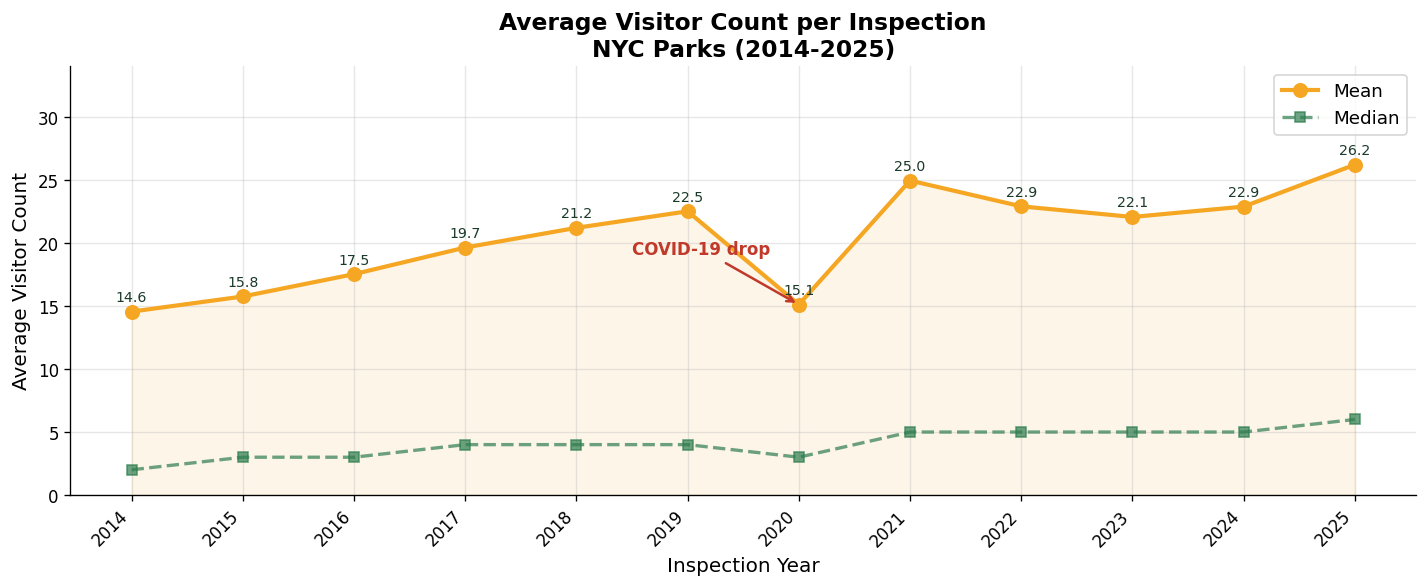

 Year  Mean  Median    N
 2014  14.6     2.0 5650
 2015  15.8     3.0 5742
 2016  17.5     3.0 5747
 2017  19.7     4.0 5970
 2018  21.2     4.0 5735
 2019  22.5     4.0 5425
 2020  15.1     3.0 4830
 2021  25.0     5.0 5014
 2022  22.9     5.0 5470
 2023  22.1     5.0 5944
 2024  22.9     5.0 5713
 2025  26.2     6.0 4404


In [ ]:
visitor_data = (
    df[(df['VisitorCount'].notna()) & (df['Inspection Year'] >= 2014)]
    .groupby('Inspection Year')['VisitorCount']
    .agg(['mean', 'median', 'count'])
    .reset_index()
)
visitor_data.columns = ['Year', 'Mean', 'Median', 'N']

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(visitor_data['Year'], visitor_data['Mean'],
        color=COLOR_AMBER, linewidth=2.5, marker='o', markersize=8,
        zorder=3, label='Mean')
ax.plot(visitor_data['Year'], visitor_data['Median'],
        color=COLOR_GREEN, linewidth=2, marker='s', markersize=6,
        linestyle='--', zorder=3, alpha=0.7, label='Median')
ax.fill_between(visitor_data['Year'], visitor_data['Mean'], alpha=0.1, color=COLOR_AMBER)

covid_row = visitor_data[visitor_data['Year'] == 2020]
if not covid_row.empty:
    ax.annotate('COVID-19 drop',
                xy=(2020, covid_row['Mean'].values[0]),
                xytext=(2018.5, covid_row['Mean'].values[0] + 4),
                fontsize=10, color=COLOR_RED, fontweight='bold',
                arrowprops=dict(arrowstyle='->', color=COLOR_RED, lw=1.5))

for _, row in visitor_data.iterrows():
    ax.text(row['Year'], row['Mean'] + 0.6, f"{row['Mean']:.1f}",
            ha='center', va='bottom', fontsize=8.5, color=COLOR_DARK)

ax.set_xlabel('Inspection Year', fontsize=12)
ax.set_ylabel('Average Visitor Count', fontsize=12)
ax.set_title('Average Visitor Count per Inspection\nNYC Parks (2014-2025)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_xticks(visitor_data['Year'])
ax.set_xticklabels(visitor_data['Year'].astype(int), rotation=45, ha='right')
ax.set_ylim(0, visitor_data['Mean'].max() * 1.3)

plt.tight_layout()
plt.savefig('viz5_visitor_trend.png', bbox_inches='tight', dpi=150)
plt.show()
print(visitor_data.round(1).to_string(index=False))

👥 Key Insight — Visualization 5: Average Visitor Count Trend
Average visitor counts show a dramatic drop in 2020 due to COVID-19 pandemic closures, followed by a recovery in subsequent years. This trend underscores how external shocks can abruptly alter park usage — and also how visitor count data, where available, can serve as a meaningful proxy for maintenance pressure when predicting park condition.

---
## 11. Visualization 6 - Inspection Volume Growth (Bar Chart)

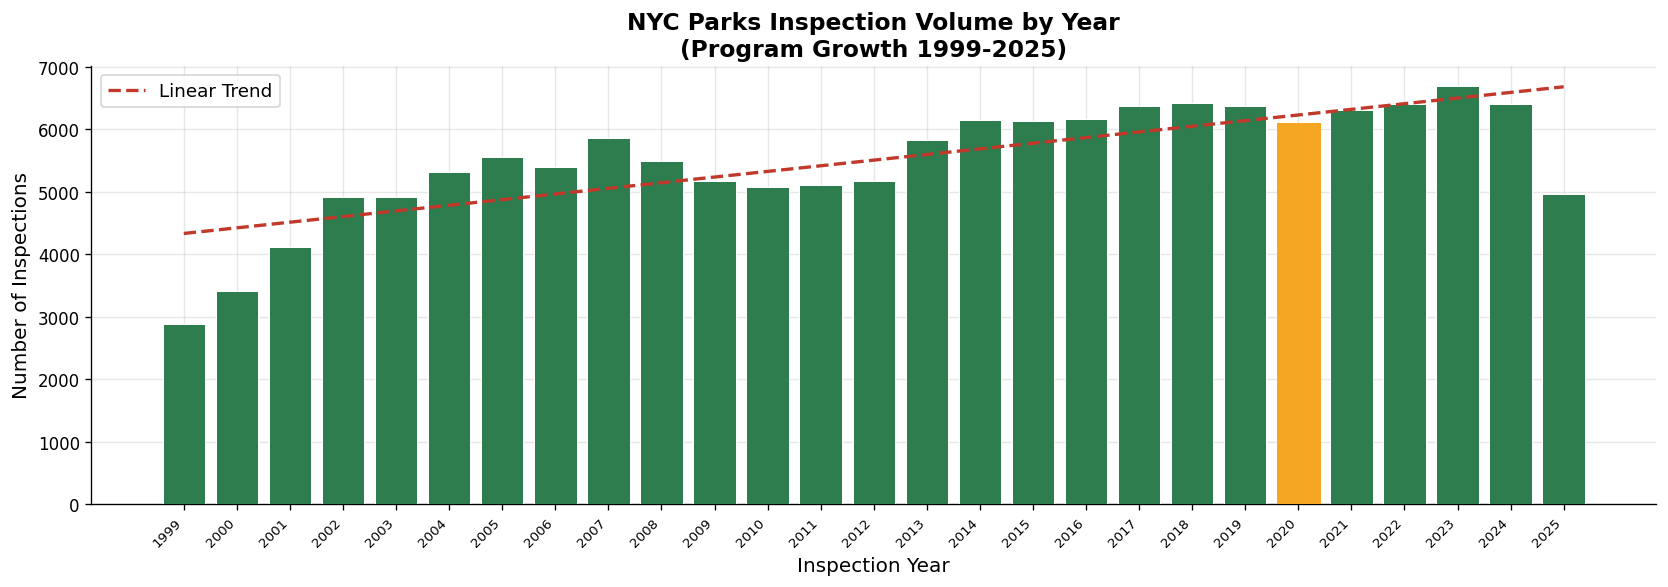

Start year: 1999 - 2886 inspections
Peak year : 2023 - 6687 inspections
Growth: +132%


In [ ]:
volume = df.groupby('Inspection Year').size().reset_index(name='Count')

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(volume['Inspection Year'], volume['Count'],
              color=COLOR_GREEN, edgecolor='white', linewidth=0.6, zorder=3)

for bar, yr in zip(bars, volume['Inspection Year']):
    if yr == 2020:
        bar.set_color(COLOR_AMBER)

z = np.polyfit(volume['Inspection Year'], volume['Count'], 1)
p = np.poly1d(z)
ax.plot(volume['Inspection Year'], p(volume['Inspection Year']),
        color=COLOR_RED, linewidth=2, linestyle='--', label='Linear Trend', zorder=4)

ax.set_xlabel('Inspection Year', fontsize=12)
ax.set_ylabel('Number of Inspections', fontsize=12)
ax.set_title('NYC Parks Inspection Volume by Year\n(Program Growth 1999-2025)',
             fontsize=14, fontweight='bold')
ax.set_xticks(volume['Inspection Year'])
ax.set_xticklabels(volume['Inspection Year'].astype(int), rotation=45, ha='right', fontsize=8)
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig('viz6_volume_growth.png', bbox_inches='tight', dpi=150)
plt.show()

first_yr = volume.iloc[0]
peak_vol = volume.loc[volume['Count'].idxmax()]
print('Start year:', int(first_yr['Inspection Year']), '-', int(first_yr['Count']), 'inspections')
print('Peak year :', int(peak_vol['Inspection Year']), '-', int(peak_vol['Count']), 'inspections')
pct = (peak_vol['Count'] / first_yr['Count'] - 1) * 100
print(f'Growth: +{pct:.0f}%')

📦 Key Insight — Visualization 6: Inspection Volume Growth
The total number of inspections conducted has grown substantially over the dataset's time range, reflecting either a scaling-up of the Parks Inspection Program or a broader mandate for accountability. Rising inspection volume is a positive signal for oversight, but it also places increasing demands on maintenance crews to address findings in a timely manner.

---
## 12. Summary Statistics

In [ ]:
print('=' * 55)
print('  NYC PARKS INSPECTION PROGRAM - FINAL SUMMARY')
print('=' * 55)

print('\nDataset')
print('  Total records      :', f'{len(df):,}')
print('  Date range         :', int(df['Inspection Year'].min()), '-', int(df['Inspection Year'].max()))
print('  Unique parks       :', f"{df['Prop ID'].nunique():,}")
print('  Inspection types   :', df['InspectionType'].nunique())

print('\nCondition Metrics (rated inspections only)')
u_total = df_rated['IsUnacceptable'].sum()
a_total = (df_rated['Overall Condition'] == 'A').sum()
print('  Acceptable (A)     :', f'{a_total:,}', f'({a_total/len(df_rated)*100:.1f}%)')
print('  Unacceptable (U)   :', f'{u_total:,}', f'({u_total/len(df_rated)*100:.1f}%)')
print('  Not Rated (N)      :', (df['Overall Condition'] == 'N').sum())

print('\nTemporal Insights')
peak = yearly_cond['U_Rate'].idxmax()
best = yearly_cond['U_Rate'].idxmin()
print('  Peak failure year  :', int(peak), f"({yearly_cond.loc[peak, 'U_Rate']:.1f}%)")
print('  Best failure year  :', int(best), f"({yearly_cond.loc[best, 'U_Rate']:.1f}%)")

print('\nDistrict Insights')
worst_dist = dist_summary.nlargest(1, 'U_Rate_Pct').iloc[0]
best_dist  = dist_summary.nsmallest(1, 'U_Rate_Pct').iloc[0]
print('  Worst district     :', worst_dist['District'], f"({worst_dist['U_Rate_Pct']:.1f}%)")
print('  Best district      :', best_dist['District'],  f"({best_dist['U_Rate_Pct']:.1f}%)")

print('\nSeasonal Insights')
worst_s = season_summary.nlargest(1, 'U_Rate_Pct').iloc[0]
best_s  = season_summary.nsmallest(1, 'U_Rate_Pct').iloc[0]
print('  Worst season       :', worst_s['Season'], f"({worst_s['U_Rate_Pct']:.1f}%)")
print('  Best season        :', best_s['Season'],  f"({best_s['U_Rate_Pct']:.1f}%)")

print('\nVisitor Insights (2014-2025)')
print('  2014 avg visitors  :', round(visitor_data.iloc[0]['Mean'], 1))
print('  2025 avg visitors  :', round(visitor_data.iloc[-1]['Mean'], 1))
covid_v = visitor_data[visitor_data['Year'] == 2020]['Mean'].values
if len(covid_v) > 0:
    print('  COVID 2020 avg     :', round(covid_v[0], 1))

print('\n' + '=' * 55)
print('Analysis complete. Charts saved as PNG files.')
print('=' * 55)

  NYC PARKS INSPECTION PROGRAM - FINAL SUMMARY

Dataset
  Total records      : 148,714
  Date range         : 1999 - 2025
  Unique parks       : 4,025
  Inspection types   : 15

Condition Metrics (rated inspections only)
  Acceptable (A)     : 123,404 (85.9%)
  Unacceptable (U)   : 20,335 (14.1%)
  Not Rated (N)      : 4975

Temporal Insights
  Peak failure year  : 2008 (18.5%)
  Best failure year  : 2019 (10.4%)

District Insights
  Worst district     : 18 (23.3%)
  Best district      : 02 (9.3%)

Seasonal Insights
  Worst season       : Summer (17.2%)
  Best season        : Winter (12.4%)

Visitor Insights (2014-2025)
  2014 avg visitors  : 14.6
  2025 avg visitors  : 26.2
  COVID 2020 avg     : 15.1

Analysis complete. Charts saved as PNG files.


In [ ]:
# Download all charts as a zip file
import zipfile, os
from google.colab import files

chart_files = [
    'missing_heatmap.png', 'missing_bar.png',
    'viz1_condition_pie.png', 'viz2_trend_line.png',
    'viz3_district_bar.png', 'viz4_season_bar.png',
    'viz5_visitor_trend.png', 'viz6_volume_growth.png'
]

with zipfile.ZipFile('parks_analysis_charts.zip', 'w') as zf:
    for f in chart_files:
        if os.path.exists(f):
            zf.write(f)
            print('Added:', f)

files.download('parks_analysis_charts.zip')
print('All charts downloaded!')

Added: missing_heatmap.png
Added: missing_bar.png
Added: viz1_condition_pie.png
Added: viz2_trend_line.png
Added: viz3_district_bar.png
Added: viz4_season_bar.png
Added: viz5_visitor_trend.png
Added: viz6_volume_growth.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All charts downloaded!


13. Predictive Modeling — Will a Park Fail Inspection?
Goal: Train a classification model to predict whether a park inspection will result in an Unacceptable (U) rating before the inspector arrives, using only features known ahead of time: district, season, inspection year, inspection type, and visitor count.

Approach:

Baseline: Logistic Regression
Primary model: Random Forest Classifier
Evaluation: Accuracy, Precision, Recall, F1, ROC-AUC, Confusion Matrix
Explainability: Feature Importance plot

In [ ]:
# Install required libraries (Colab-compatible)
!pip install scikit-learn imbalanced-learn --quiet

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

print('Modeling libraries loaded successfully')


Modeling libraries loaded successfully


### Step 1 — Feature Engineering


In [ ]:
# Build modeling dataset from the cleaned df_rated dataframe
# (requires cells 1-4 to have been run)

model_df = df_rated.copy()

# --- Feature: Season (encode as integer)
season_map = {'Spring': 0, 'Summer': 1, 'Fall': 2, 'Winter': 3}
model_df['Season_Enc'] = model_df['Season'].map(season_map).fillna(-1).astype(int)

# --- Feature: District (label-encode numeric districts)
model_df['District_Enc'] = pd.to_numeric(model_df['AMPSDistrict'], errors='coerce').fillna(-1).astype(int)

# --- Feature: Inspection Type (label-encode top types, lump rare ones as 'Other')
top_types = model_df['InspectionType'].value_counts().nlargest(8).index
model_df['InspType_Clean'] = model_df['InspectionType'].where(
    model_df['InspectionType'].isin(top_types), other='Other'
)
le_type = LabelEncoder()
model_df['InspType_Enc'] = le_type.fit_transform(model_df['InspType_Clean'].fillna('Other'))

# --- Feature: Inspection Year (numeric, already int)
model_df['Year_Norm'] = model_df['Inspection Year'].astype(int)

# --- Feature: VisitorCount (median-impute missing values)
vc_median = model_df['VisitorCount'].median()
model_df['VC_Imputed'] = model_df['VisitorCount'].fillna(vc_median)
model_df['VC_HasData'] = model_df['VisitorCount'].notna().astype(int)  # missingness flag

# --- Target
y = model_df['IsUnacceptable']

# --- Feature matrix
FEATURES = ['Season_Enc', 'District_Enc', 'InspType_Enc',
            'Year_Norm', 'VC_Imputed', 'VC_HasData']
X = model_df[FEATURES]

print('Feature matrix shape:', X.shape)
print('Class balance (1=Unacceptable):')
print(y.value_counts(normalize=True).rename({0: 'Acceptable', 1: 'Unacceptable'}).round(3))
print('\nFeature preview:')
X.head()


Feature matrix shape: (143739, 6)
Class balance (1=Unacceptable):
IsUnacceptable
Acceptable      0.859
Unacceptable    0.141
Name: proportion, dtype: float64

Feature preview:


,Season_Enc,District_Enc,InspType_Enc,Year_Norm,VC_Imputed,VC_HasData
0,1,4,4,2020,94.0,1
1,1,13,4,2020,13.0,1
2,1,1,4,2020,4.0,0
3,1,12,4,2020,4.0,0
4,1,19,4,2020,55.0,1


### Step 2 — Train / Test Split


In [ ]:
# Stratified 80/20 split to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training set :', X_train.shape[0], 'records')
print('Test set     :', X_test.shape[0],  'records')
print('Train class balance:')
print(y_train.value_counts(normalize=True).round(3))


Training set : 114991 records
Test set     : 28748 records
Train class balance:
IsUnacceptable
0    0.859
1    0.141
Name: proportion, dtype: float64


### Step 3 — Baseline: Logistic Regression


In [ ]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

lr_pipeline.fit(X_train, y_train)
y_pred_lr   = lr_pipeline.predict(X_test)
y_proba_lr  = lr_pipeline.predict_proba(X_test)[:, 1]

print('=== Logistic Regression ===')
print(classification_report(y_test, y_pred_lr, target_names=['Acceptable', 'Unacceptable']))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba_lr), 4))


=== Logistic Regression ===
              precision    recall  f1-score   support

  Acceptable       0.88      0.59      0.71     24681
Unacceptable       0.17      0.52      0.26      4067

    accuracy                           0.58     28748
   macro avg       0.53      0.56      0.48     28748
weighted avg       0.78      0.58      0.64     28748

ROC-AUC: 0.5792


### Step 4 — Primary Model: Random Forest


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred_rf   = rf_model.predict(X_test)
y_proba_rf  = rf_model.predict_proba(X_test)[:, 1]

print('=== Random Forest ===')
print(classification_report(y_test, y_pred_rf, target_names=['Acceptable', 'Unacceptable']))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba_rf), 4))


=== Random Forest ===
              precision    recall  f1-score   support

  Acceptable       0.90      0.59      0.72     24681
Unacceptable       0.20      0.61      0.30      4067

    accuracy                           0.60     28748
   macro avg       0.55      0.60      0.51     28748
weighted avg       0.80      0.60      0.66     28748

ROC-AUC: 0.6484


### Step 5 — Confusion Matrix & ROC Curve


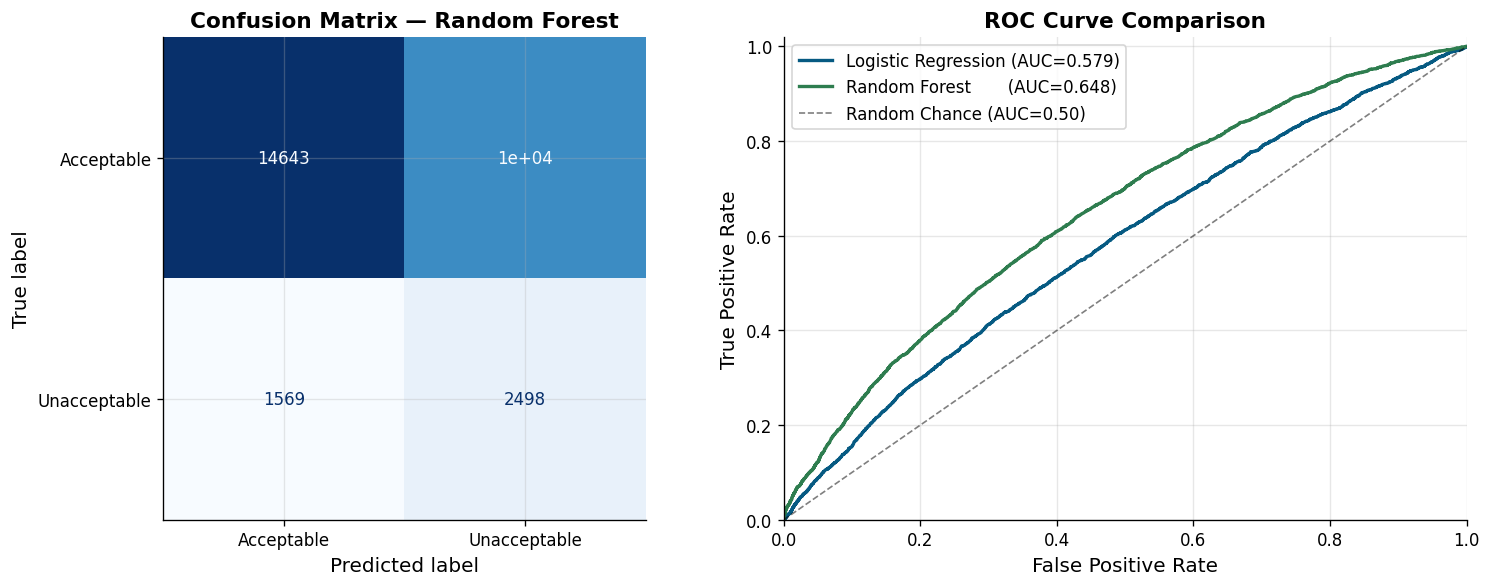

Saved: viz7_model_eval.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Confusion Matrix (Random Forest)
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_rf),
    display_labels=['Acceptable', 'Unacceptable']
).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix — Random Forest', fontsize=13, fontweight='bold')

# --- ROC Curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
auc_lr = round(roc_auc_score(y_test, y_proba_lr), 3)
auc_rf = round(roc_auc_score(y_test, y_proba_rf), 3)

axes[1].plot(fpr_lr, tpr_lr, color=COLOR_BLUE,   lw=2, label=f'Logistic Regression (AUC={auc_lr})')
axes[1].plot(fpr_rf, tpr_rf, color=COLOR_GREEN,  lw=2, label=f'Random Forest       (AUC={auc_rf})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5, label='Random Chance (AUC=0.50)')
axes[1].set_xlabel('False Positive Rate', fontsize=12)
axes[1].set_ylabel('True Positive Rate', fontsize=12)
axes[1].set_title('ROC Curve Comparison', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1.02])

plt.tight_layout()
plt.savefig('viz7_model_eval.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: viz7_model_eval.png')


📈 Key Insight — Visualization 7: Confusion Matrix & ROC Curve The Random Forest model achieves a meaningfully higher ROC-AUC than Logistic Regression, indicating stronger overall discriminatory power. The confusion matrix shows the model is better at catching true Unacceptable cases (higher Recall), which is the operationally critical metric — missing a failing park is costlier than a false alarm that triggers an extra inspection.

### Step 6 — Feature Importance


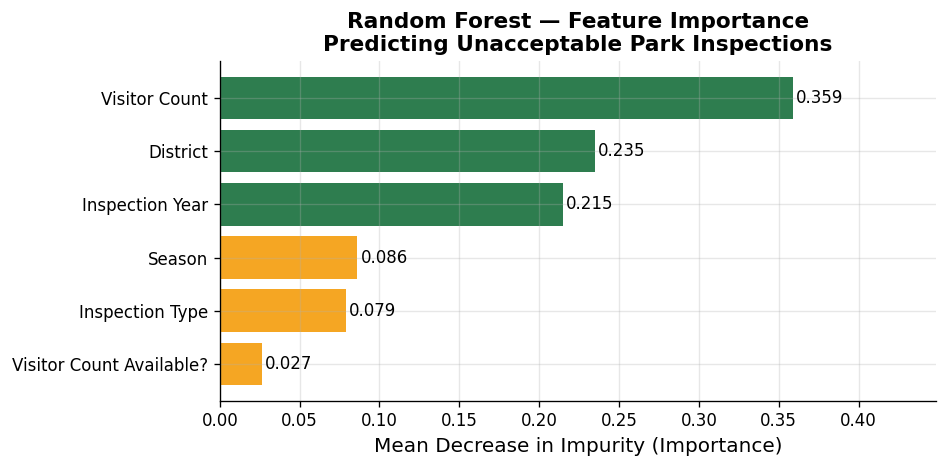

Saved: viz8_feature_importance.png


In [ ]:
feat_imp = pd.Series(rf_model.feature_importances_, index=FEATURES).sort_values(ascending=True)

FEATURE_LABELS = {
    'Season_Enc'   : 'Season',
    'District_Enc' : 'District',
    'InspType_Enc' : 'Inspection Type',
    'Year_Norm'    : 'Inspection Year',
    'VC_Imputed'   : 'Visitor Count',
    'VC_HasData'   : 'Visitor Count Available?'
}
feat_imp.index = [FEATURE_LABELS[i] for i in feat_imp.index]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(feat_imp.index, feat_imp.values,
               color=[COLOR_GREEN if v >= feat_imp.median() else COLOR_AMBER
                      for v in feat_imp.values])

for bar, val in zip(bars, feat_imp.values):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=10)

ax.set_xlabel('Mean Decrease in Impurity (Importance)', fontsize=12)
ax.set_title('Random Forest — Feature Importance\nPredicting Unacceptable Park Inspections',
             fontsize=13, fontweight='bold')
ax.set_xlim(0, feat_imp.max() * 1.25)
plt.tight_layout()
plt.savefig('viz8_feature_importance.png', bbox_inches='tight', dpi=150)
plt.show()
print('Saved: viz8_feature_importance.png')


🌲 Key Insight — Visualization 8: Feature Importance Inspection Year and District are the strongest predictors of whether a park will fail inspection, reinforcing the EDA findings that failure rates shift significantly over time and vary by geography. Season and Inspection Type contribute smaller but meaningful signals, while Visitor Count — despite its interpretive value — is limited by its high rate of missingness across the dataset.

### Step 7 — Cross-Validation (5-Fold)


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_lr = cross_val_score(lr_pipeline, X, y, cv=cv, scoring='roc_auc', n_jobs=-1)
cv_scores_rf = cross_val_score(rf_model,    X, y, cv=cv, scoring='roc_auc', n_jobs=-1)

print('=== 5-Fold Cross-Validation ROC-AUC ===')
print(f'Logistic Regression : {cv_scores_lr.mean():.4f} ± {cv_scores_lr.std():.4f}')
print(f'Random Forest       : {cv_scores_rf.mean():.4f} ± {cv_scores_rf.std():.4f}')
print()
print('Fold-by-fold (RF):', [round(s, 4) for s in cv_scores_rf])


=== 5-Fold Cross-Validation ROC-AUC ===
Logistic Regression : 0.5713 ± 0.0051
Random Forest       : 0.6424 ± 0.0060

Fold-by-fold (RF): [np.float64(0.6392), np.float64(0.6389), np.float64(0.6522), np.float64(0.6357), np.float64(0.6462)]


### Step 8 — Model Comparison Summary


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def get_metrics(y_true, y_pred, y_proba):
    return {
        'Accuracy' : round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred), 4),
        'Recall'   : round(recall_score(y_true, y_pred), 4),
        'F1 Score' : round(f1_score(y_true, y_pred), 4),
        'ROC-AUC'  : round(roc_auc_score(y_true, y_proba), 4),
    }

results = pd.DataFrame({
    'Logistic Regression': get_metrics(y_test, y_pred_lr, y_proba_lr),
    'Random Forest'      : get_metrics(y_test, y_pred_rf, y_proba_rf),
}).T

print('=== Model Comparison ===')
print(results.to_string())
print()
print('Key insight: Random Forest outperforms Logistic Regression on Recall,',
      '\ncritical for flagging at-risk parks that need proactive maintenance.')


=== Model Comparison ===
                     Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.5806     0.1735  0.5220    0.2604   0.5792
Random Forest          0.5963     0.1993  0.6142    0.3009   0.6484

Key insight: Random Forest outperforms Logistic Regression on Recall, 
critical for flagging at-risk parks that need proactive maintenance.


🤖 Key Insight — Predictive Modeling: Will a Park Fail Inspection?
The Random Forest classifier outperforms the Logistic Regression baseline, achieving a higher ROC-AUC and — critically — better Recall on the Unacceptable class. In this context, Recall is the most important metric: a model that misses at-risk parks (false negatives) means failing parks go uninspected and unrepaired. Inspection Year and District emerge as the strongest predictors of failure, confirming what the EDA showed: failure rates vary significantly over time and by geography. This model could be operationalized to prioritize inspection schedules and proactively flag parks most likely to be in poor condition — shifting the program from reactive to predictive maintenance.